# Self-Organizing Maps (SOMs) Notebook - Alaska Cyclones
- Plot box plots of decadal changes in sea ice freeze up at each of the four villages

**Notebook by Alice DuVivier - July 2026**

In [1]:
import pandas as pd
import xarray as xr
import cftime
import numpy as np
import pandas as pd
from itertools import product
import cartopy
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
from datetime import timedelta
from itertools import product
import cmocean
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.ticker as mtick

## Set village and node of choice

In [2]:
# set paired lists name and node of interest
village_names = ['Nome','Savoonga','Gambell','Shishmaref','Unalakleet']
village_lats =  [64.501, 63.694, 63.776, 66.257, 63.879]
village_lons =  [-165.406, -170.479, -171.701, -166.072, -160.790]

# set xloc and yloc values - determined from another notebook finding nearest atmospheric point that is over mostly ocean
village_xlocs_atm = [57,55,55,65,55]
village_ylocs_atm = [98,78,73,95,115]

village_xlocs_ice = [261,238,237,289,263]
village_ylocs_ice = [270,234,224,254,310]

nvillages  = len(village_names)
print(nvillages)

5


## Load data
- Daily sea ice concentration

In [3]:
# set path where the som finalist files are
dir_in = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/DATA/SOM_alaska_cyclones/data_for_composites/'

In [4]:
# load historical data
var_in = 'aice_d'
# Load data for larger area than only training area - set file name
fin_training = var_in+'_autumn_hist_decadal_alaska_cam_grid'

# load data
ds_hist = xr.open_dataset(dir_in+fin_training+'.nc')

In [5]:
# load rcp60 data
var_in = 'aice_d'
# Load data for larger area than only training area - set file name
fin_training = var_in+'_autumn_rcp60_decadal_alaska_cam_grid'

# load data
ds_rcp60 = xr.open_dataset(dir_in+fin_training+'.nc')

## Get data just at villages

In [6]:
## historical
data_in = ds_hist[var_in]

# preallocate array
nens = len(data_in.ensemble)
ndec = len(data_in.decades)
ndays = len(data_in.autumn_days)
data_array = np.zeros([nvillages,nens,ndec,ndays])

# loop through each year to get the data
for index, vv in enumerate(village_names):
    print(vv)
    # read in xloc and yloc for this village
    xloc = village_xlocs_ice[index]
    yloc = village_ylocs_ice[index]
    # keep data at this grid point only
    temp = data_in.isel(nj=slice(xloc,xloc+1),ni=slice(yloc,yloc+1))
    temp = temp.isel(nj=0,ni=0)
    temp = temp.load()
    data_array[index,:,:,:] = temp

# convert the numpy arrays to xarrays for easier plotting
sic_villages_hist = xr.DataArray(data_array,dims=('villages','ensemble','decades','autumn_days'))
sic_villages_hist['villages'] = village_names
sic_villages_hist['ensemble'] = data_in.ensemble
sic_villages_hist['decades'] = data_in.decades
sic_villages_hist['autumn_days'] = data_in.autumn_days

Nome
Savoonga
Gambell
Shishmaref
Unalakleet


In [7]:
## future
data_in = ds_rcp60[var_in]

# preallocate array
nens = len(data_in.ensemble)
ndec = len(data_in.decades)
ndays = len(data_in.autumn_days)
data_array = np.zeros([nvillages,nens,ndec,ndays])

# loop through each year to get the data
for index, vv in enumerate(village_names):
    print(vv)
    # read in xloc and yloc for this village
    xloc = village_xlocs_ice[index]
    yloc = village_ylocs_ice[index]
    # keep data at this grid point only
    temp = data_in.isel(nj=slice(xloc,xloc+1),ni=slice(yloc,yloc+1))
    temp = temp.isel(nj=0,ni=0)
    temp = temp.load()
    data_array[index,:,:,:] = temp

# convert the numpy arrays to xarrays for easier plotting
sic_villages_rcp60 = xr.DataArray(data_array,dims=('villages','ensemble','decades','autumn_days'))
sic_villages_rcp60['villages'] = village_names
sic_villages_rcp60['ensemble'] = data_in.ensemble
sic_villages_rcp60['decades'] = data_in.decades
sic_villages_rcp60['autumn_days'] = data_in.autumn_days

Nome
Savoonga
Gambell
Shishmaref
Unalakleet


In [8]:
# concatenate data into a single dataset
sic_villages_autumn = xr.concat([sic_villages_hist, sic_villages_rcp60], dim='decades')

### Get decadal ensemble means and standard deviations
- First need to break data into each of the three years that go into a decade

In [9]:
sic_villages_autumn.shape

(5, 9, 15, 366)

In [10]:
# break this into an array with dimensions ensembles, decades, year, autumn_days (122)

# get number of days in autumn months
ndays = 30 + 31 +30 + 31
print(ndays)

# set number of years in each decade
nyears = 3

122


In [11]:
# make new year and day arrays
year = np.repeat(np.arange(nyears), ndays)
day = np.tile(np.arange(ndays), nyears)

# convert day to julian days
jday = day + 244

In [12]:
# break up the "autumn_days" dimension
sic_villages_autumn_new = (
    sic_villages_autumn.assign_coords(
        years=("autumn_days", year),
        julian_day=("autumn_days", jday)
    ).set_index(autumn_days=["years", "julian_day"]).unstack("autumn_days"))

In [13]:
sic_villages_autumn_new.shape

(5, 9, 15, 3, 122)

### Get decadal ensemble means and standard deviations

In [14]:
# get mean and standard deviation for each decade
sic_autumn_avg = sic_villages_autumn_new.mean(dim=['ensemble','years'])
sic_autumn_std = sic_villages_autumn_new.std(dim=['ensemble','years'])

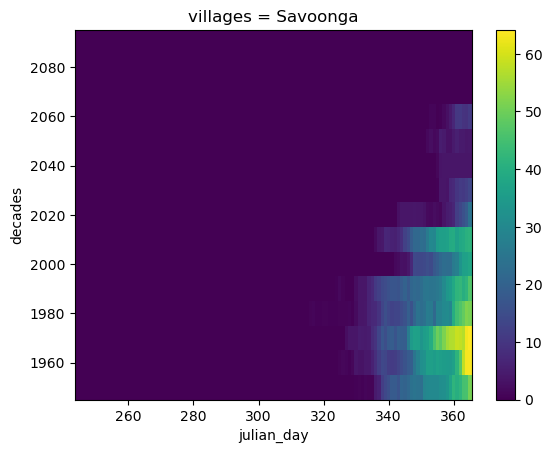

In [15]:
# look at the data
sic_autumn_avg.isel(villages=1).plot()

### Get day of freeze up
- First day that SIC > 15% (we will not worry about temporary freeze ups here)

In [16]:
# combine the ensemble and years dimensions since these are essentially equal ensembles for each decade
sic_villages_autumn_stacked = sic_villages_autumn_new.stack(all=("ensemble","years"))

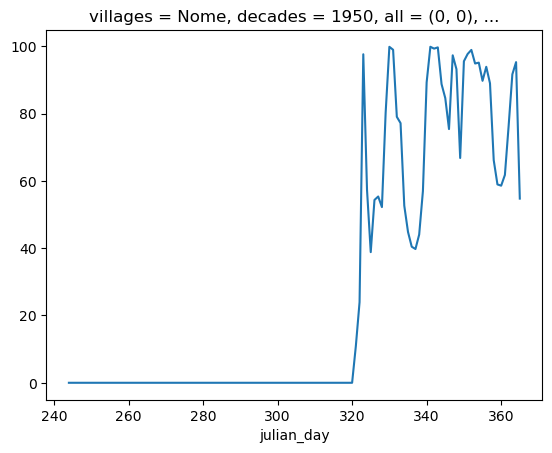

In [17]:
# look at one ensemble and one year
sic_villages_autumn_stacked.isel(villages=0,decades=0,all=0).plot()

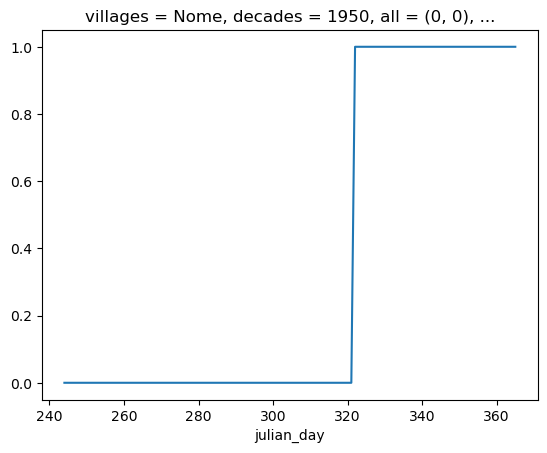

In [18]:
# get mask of where concentrations are above 15%
mask_zeros = xr.zeros_like(sic_villages_autumn_stacked)

# then set anywhere where SIC >= 15% to 1
freeze_up_villages_autumn_stacked = mask_zeros.where(sic_villages_autumn_stacked <= 15, 1)

# look at one ensemble and one year to verify it worked
freeze_up_villages_autumn_stacked.isel(villages=0,decades=0,all=0).plot()

In [19]:
# Find the first instance where the mask is equal to 1, that's the day of freeze up
# also make sure that if there are no values of 1 (i.e. does not freeze) then we don't include those or it'll mess up and suggest too early

is_one = freeze_up_villages_autumn_stacked == 1
has_one = is_one.any(dim='julian_day')
first_idx = is_one.argmax(dim='julian_day')
first_julian_day = freeze_up_villages_autumn_stacked['julian_day'].isel(julian_day=first_idx).where(has_one)

In [20]:
first_julian_day

<xarray.DataArray 'julian_day' (villages: 5, decades: 15, all: 27)> Size: 16kB
array([[[322., 335., 357., ..., 323., 337., 360.],
        [357., 347., 332., ..., 334., 340., 353.],
        [339., 338., 338., ..., 337., 340., 342.],
        ...,
        [361.,  nan,  nan, ...,  nan,  nan, 353.],
        [ nan,  nan, 365., ...,  nan,  nan,  nan],
        [ nan,  nan,  nan, ...,  nan,  nan,  nan]],

       [[333., 336., 356., ..., 355., 336., 364.],
        [360.,  nan, 342., ..., 326.,  nan, 363.],
        [347., 336., 353., ..., 354., 346., 353.],
        ...,
        [ nan,  nan,  nan, ...,  nan,  nan,  nan],
        [ nan,  nan,  nan, ...,  nan,  nan,  nan],
        [ nan,  nan,  nan, ...,  nan,  nan,  nan]],

       [[341., 336., 355., ..., 357., 338., 365.],
        [363., 364., 342., ..., 335.,  nan, 362.],
        [348., 338., 352., ..., 357., 343., 359.],
        ...,
        [ nan,  nan,  nan, ...,  nan,  nan,  nan],
        [ nan,  nan,  nan, ...,  nan,  nan,  nan],
        [ nan,  nan,  nan, ...,  nan,  nan,  nan]],

       [[324., 334., 353., ..., 324., 335., 359.],
        [340., 347., 338., ..., 334., 345., 339.],
        [342., 334., 339., ..., 336., 338., 341.],
        ...,
        [364.,  nan,  nan, ...,  nan,  nan,  nan],
        [ nan,  nan,  nan, ...,  nan,  nan,  nan],
        [ nan,  nan,  nan, ...,  nan,  nan,  nan]],

       [[332., 342., 358., ..., 354., 342., 359.],
        [337., 345., 354., ..., 343., 334., 360.],
        [341., 346., 350., ..., 337., 355., 343.],
        ...,
        [ nan,  nan,  nan, ...,  nan,  nan,  nan],
        [ nan,  nan,  nan, ...,  nan,  nan,  nan],
        [ nan,  nan,  nan, ...,  nan,  nan,  nan]]])
Coordinates:
    julian_day  (villages, decades, all) int64 16kB 322 335 357 ... 244 244 244
  * villages    (villages) <U10 200B 'Nome' 'Savoonga' ... 'Unalakleet'
  * decades     (decades) int64 120B 1950 1960 1970 1980 ... 2060 2070 2080 2090
  * all         (all) object 216B MultiIndex
  * ensemble    (all) int64 216B 0 0 0 1 1 1 2 2 2 3 3 ... 5 5 6 6 6 7 7 7 8 8 8
  * years       (all) int64 216B 0 1 2 0 1 2 0 1 2 0 1 ... 1 2 0 1 2 0 1 2 0 1 2

## Break Data into decades

In [21]:
# choose subset of decades to do initial analysis
decades = [1950,2000,2050]
decades_str = ['1950','2000','2050']

In [22]:
# data for each decade in subset of decades
freeze_up_1950 = first_julian_day.sel(decades=1950)
freeze_up_2000 = first_julian_day.sel(decades=2000)
freeze_up_2050 = first_julian_day.sel(decades=2050)

## Count instances where there *is* a freeze up date

In [23]:
def clean(arr):
    """Drop NaNs from a numpy array for boxplot compatibility."""
    arr = np.asarray(arr)
    return arr[~np.isnan(arr)]

In [24]:
## 1950
data_in = freeze_up_1950

# preallocate array
data_array = np.zeros([nvillages,2])

# loop through each year to get the data
for index, vv in enumerate(village_names):
    #print(vv)
    data_sub = data_in.isel(villages=index)
    # clean data of nans then count number of years where there IS freeze up
    count = len(clean(data_sub))
    # save raw number of counts
    data_array[index,0] = count
    # calculate frequency as a fraction of the total dates that map to this node in this decade
    data_array[index,1] = 100.0*(count/27)

# convert the numpy arrays to xarrays for easier plotting
freq_freeze_villages_1950 = xr.DataArray(data_array,dims=('villages','methods'))
freq_freeze_villages_1950['villages'] = village_names

In [25]:
## 2000
data_in = freeze_up_2000

# preallocate array
data_array = np.zeros([nvillages,2])

# loop through each year to get the data
for index, vv in enumerate(village_names):
    #print(vv)
    data_sub = data_in.isel(villages=index)
    # clean data of nans then count number of years where there IS freeze up
    count = len(clean(data_sub))
    # save raw number of counts
    data_array[index,0] = count
    # calculate frequency as a fraction of the total dates that map to this node in this decade
    data_array[index,1] = 100.0*(count/27)

# convert the numpy arrays to xarrays for easier plotting
freq_freeze_villages_2000 = xr.DataArray(data_array,dims=('villages','methods'))
freq_freeze_villages_2000['villages'] = village_names

In [26]:
## 2050
data_in = freeze_up_2050

# preallocate array
data_array = np.zeros([nvillages,2])

# loop through each year to get the data
for index, vv in enumerate(village_names):
    #print(vv)
    data_sub = data_in.isel(villages=index)
    # clean data of nans then count number of years where there IS freeze up
    count = len(clean(data_sub))
    # save raw number of counts
    data_array[index,0] = count
    # calculate frequency as a fraction of the total dates that map to this node in this decade
    data_array[index,1] = 100.0*(count/27)

# convert the numpy arrays to xarrays for easier plotting
freq_freeze_villages_2050 = xr.DataArray(data_array,dims=('villages','methods'))
freq_freeze_villages_2050['villages'] = village_names

In [27]:
# print these differences
print('Fraction of dates with freeze up')
print('1950')
print(freq_freeze_villages_1950.values)
print('2000')
print(freq_freeze_villages_2000.values)
print('2050')
print(freq_freeze_villages_2050.values)

Fraction of dates with freeze up
1950
[[25.         92.59259259]
 [18.         66.66666667]
 [16.         59.25925926]
 [26.         96.2962963 ]
 [23.         85.18518519]]
2000
[[23.         85.18518519]
 [14.         51.85185185]
 [11.         40.74074074]
 [25.         92.59259259]
 [20.         74.07407407]]
2050
[[17.         62.96296296]
 [ 2.          7.40740741]
 [ 2.          7.40740741]
 [16.         59.25925926]
 [13.         48.14814815]]


## Plot data at the villages

In [28]:
# set output directory
dir_out = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/SOM_alaska_cyclones/analysis_v4/'

### Plot mean freeze up for all decades at villages

In [67]:
# set the decades
decades = sic_autumn_avg.decades
ndec = len(decades)

In [66]:
# set xarray to plot against
xarr_day = sic_autumn_avg.julian_day

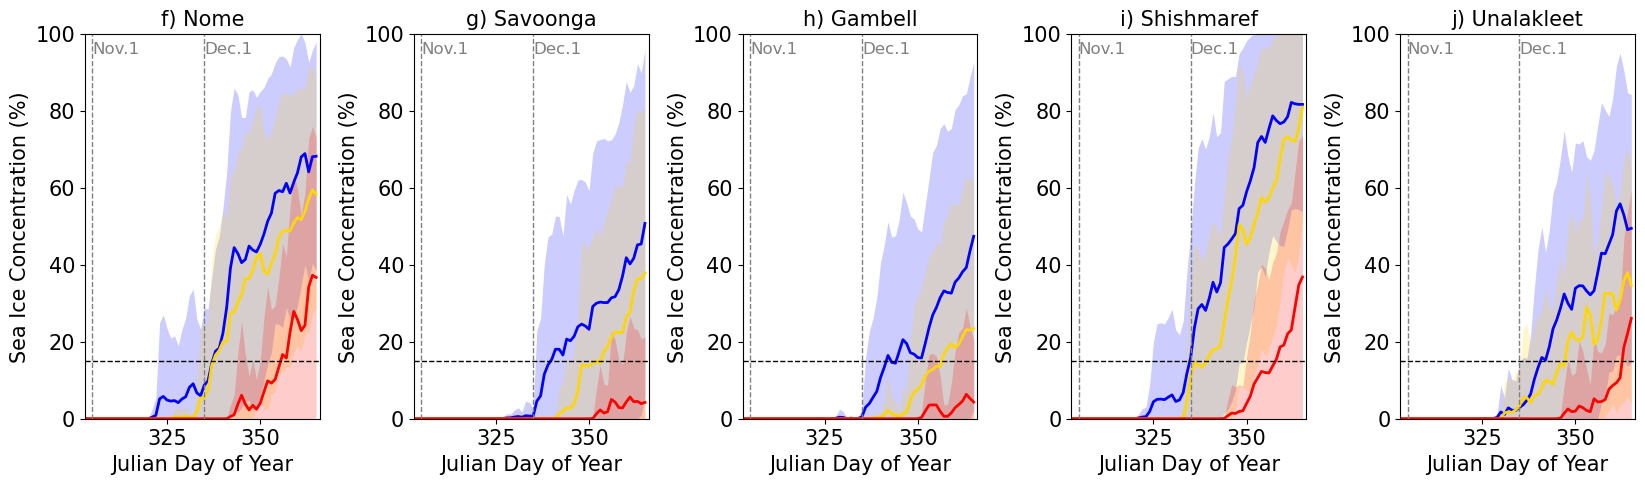

In [68]:
# Create figure
fout = 'figure_5_decadal_freeze_up'

fig, axs = plt.subplots(1, 5, figsize=(20, 5))

# Decades, colors, and legend labels
decades_plot = [1950, 2000, 2050]
colors_plot = ['blue', 'gold', 'red']
labels_plot = ['Early', 'Mid', 'Late']

# Panel labels (continuing from earlier figure panels)
panel_labels = ['f', 'g', 'h', 'i', 'j']

# Month markers
#month_days = [244, 274, 305, 335]
#month_labels = ['Sept.1', 'Oct.1', 'Nov.1', 'Dec.1']
month_days = [305, 335]
month_labels = ['Nov.1', 'Dec.1']

# Loop through villages
for n, ax in enumerate(axs):

    # Plot mean and +/- 1 standard deviation for each decade
    for decade, color, label in zip(decades_plot, colors_plot, labels_plot):

        data_avg = sic_autumn_avg.isel(villages=n).sel(decades=decade)
        data_std = sic_autumn_std.isel(villages=n).sel(decades=decade)

        # Plot mean
        ax.plot(xarr_day, data_avg, color=color, linestyle='-', linewidth=2,label=label)

        # Shade +/- 1 standard deviation
        ax.fill_between(xarr_day, np.clip(data_avg - data_std, 0, 100), np.clip(data_avg + data_std, 0, 100), color=color, alpha=0.20, linewidth=0)

    # SIC = 15% threshold
    ax.axhline(y=15, color='black', linestyle='--', linewidth=1)

    # Month markers
    for day, month in zip(month_days, month_labels):
        ax.axvline(x=day, color='grey', linestyle='--', linewidth=1)
        ax.text(day, 95, month, fontsize=12, color='grey')

    # Panel formatting
    ax.set_title(f'{panel_labels[n]}) {village_names[n]}', fontsize=15)
    ax.set_xlabel('Julian Day of Year', fontsize=15)
    ax.set_ylabel('Sea Ice Concentration (%)', fontsize=15)

    ax.set_ylim(0, 100)
    #ax.set_xlim(240,366)
    ax.set_xlim(303,366)
    #ax.set_xlim(305, 366) if n == 4 else ax.set_xlim(240, 366)

    ax.tick_params(axis='both', labelsize=15)

    # Only show legend in first panel
    #if n == 0:
    #?    ax.legend(loc='lower left', fontsize=12)

# Finalize figure
fig.subplots_adjust(wspace=0.4)

# Save figure
fig.savefig(fout + '.png', bbox_inches='tight', dpi=200)
fig.savefig(dir_out + fout + '.png', bbox_inches='tight', dpi=200)

plt.show()


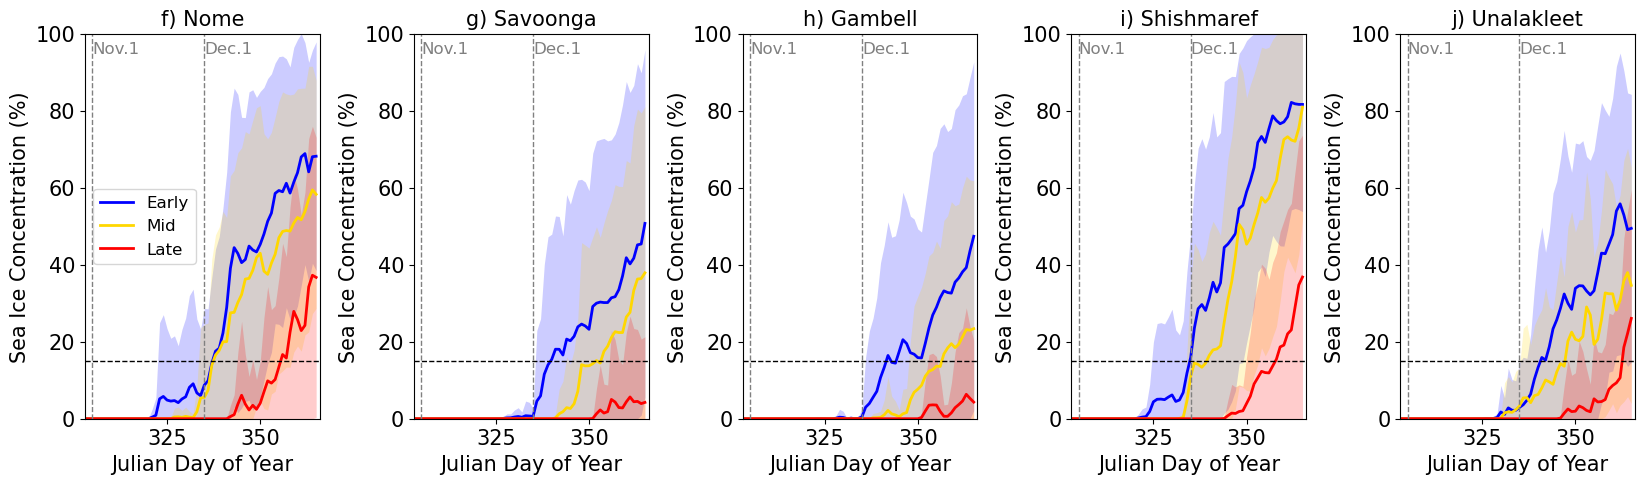

In [70]:
# Create figure
fout = 'legend_freeze_up'

fig, axs = plt.subplots(1, 5, figsize=(20, 5))

# Decades, colors, and legend labels
decades_plot = [1950, 2000, 2050]
colors_plot = ['blue', 'gold', 'red']
labels_plot = ['Early', 'Mid', 'Late']

# Panel labels (continuing from earlier figure panels)
panel_labels = ['f', 'g', 'h', 'i', 'j']

# Month markers
#month_days = [244, 274, 305, 335]
#month_labels = ['Sept.1', 'Oct.1', 'Nov.1', 'Dec.1']
month_days = [305, 335]
month_labels = ['Nov.1', 'Dec.1']

# Loop through villages
for n, ax in enumerate(axs):

    # Plot mean and +/- 1 standard deviation for each decade
    for decade, color, label in zip(decades_plot, colors_plot, labels_plot):

        data_avg = sic_autumn_avg.isel(villages=n).sel(decades=decade)
        data_std = sic_autumn_std.isel(villages=n).sel(decades=decade)

        # Plot mean
        ax.plot(xarr_day, data_avg, color=color, linestyle='-', linewidth=2,label=label)

        # Shade +/- 1 standard deviation
        ax.fill_between(xarr_day, np.clip(data_avg - data_std, 0, 100), np.clip(data_avg + data_std, 0, 100), color=color, alpha=0.20, linewidth=0)

    # SIC = 15% threshold
    ax.axhline(y=15, color='black', linestyle='--', linewidth=1)

    # Month markers
    for day, month in zip(month_days, month_labels):
        ax.axvline(x=day, color='grey', linestyle='--', linewidth=1)
        ax.text(day, 95, month, fontsize=12, color='grey')

    # Panel formatting
    ax.set_title(f'{panel_labels[n]}) {village_names[n]}', fontsize=15)
    ax.set_xlabel('Julian Day of Year', fontsize=15)
    ax.set_ylabel('Sea Ice Concentration (%)', fontsize=15)

    ax.set_ylim(0, 100)
    #ax.set_xlim(240,366)
    ax.set_xlim(303,366)
    #ax.set_xlim(305, 366) if n == 4 else ax.set_xlim(240, 366)

    ax.tick_params(axis='both', labelsize=15)

    # Only show legend in first panel
    if n == 0:
        ax.legend(loc='center left', fontsize=12)

# Finalize figure
fig.subplots_adjust(wspace=0.4)

# Save figure
fig.savefig(fout + '.png', bbox_inches='tight', dpi=200)
fig.savefig(dir_out + fout + '.png', bbox_inches='tight', dpi=200)

plt.show()


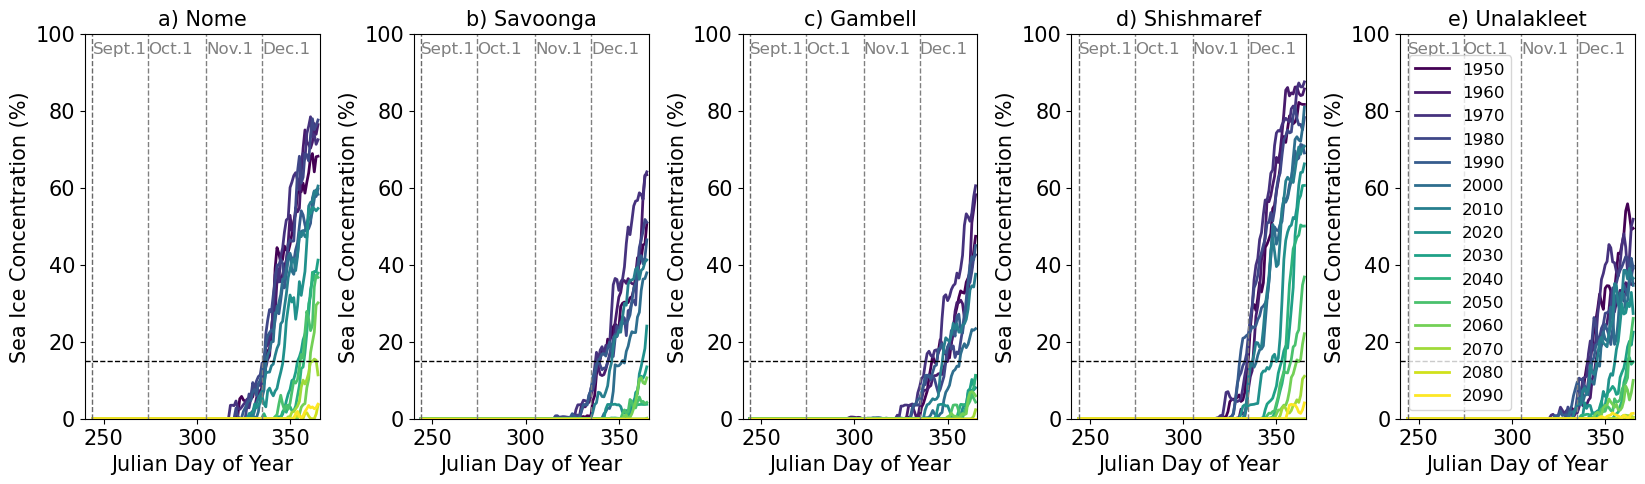

In [72]:
# create figure
fout = 'supp_decadal_freeze_up'

fig = plt.figure(figsize=(20,5))

### Plot 1  - First Village ###
ax = fig.add_subplot(1,5,1)
# plot the decadal means
n=0
for dd in range(ndec):
    ax.plot(xarr_day,sic_autumn_avg.isel(villages=n,decades=dd),color=colors[dd],linestyle='-',linewidth=2,label=str(decades[dd].values));
# add lines for SIC = 15
ax.axhline(y=15, color='black', linestyle='--', linewidth=1)
# add vertical lines for months and label them
ax.text(244,95,s="Sept.1",fontsize=12,color='grey')
ax.axvline(x=244, color='dimgrey', linestyle='--', linewidth=1)
ax.text(274,95,s="Oct.1",fontsize=12,color='grey')
ax.axvline(x=274, color='grey', linestyle='--', linewidth=1)
ax.text(305,95,s="Nov.1",fontsize=12,color='grey')
ax.axvline(x=305, color='grey', linestyle='--', linewidth=1)
ax.text(335,95,s="Dec.1",fontsize=12,color='grey')
ax.axvline(x=335, color='grey', linestyle='--', linewidth=1)
# modify plot
plt.title('a) '+village_names[n],fontsize=15)
plt.xlabel('Julian Day of Year',fontsize=15)
plt.xticks(fontsize=15)
plt.xlim([240,366])
plt.ylim([0,100])
plt.ylabel('Sea Ice Concentration (%)',fontsize=15)
plt.yticks(fontsize=15)
#plt.legend(loc='center left', fontsize=12, ncol=2)

### Plot 2  - First Village ###
ax = fig.add_subplot(1,5,2)
# plot the decadal means
n=1
for dd in range(ndec):
    ax.plot(xarr_day,sic_autumn_avg.isel(villages=n,decades=dd),color=colors[dd],linestyle='-',linewidth=2,label=str(decades[dd].values));
# add lines for SIC = 15
ax.axhline(y=15, color='black', linestyle='--', linewidth=1)
# add vertical lines for months and label them
ax.text(244,95,s="Sept.1",fontsize=12,color='grey')
ax.axvline(x=244, color='dimgrey', linestyle='--', linewidth=1)
ax.text(274,95,s="Oct.1",fontsize=12,color='grey')
ax.axvline(x=274, color='grey', linestyle='--', linewidth=1)
ax.text(305,95,s="Nov.1",fontsize=12,color='grey')
ax.axvline(x=305, color='grey', linestyle='--', linewidth=1)
ax.text(335,95,s="Dec.1",fontsize=12,color='grey')
ax.axvline(x=335, color='grey', linestyle='--', linewidth=1)
# modify plot
plt.title('b) '+village_names[n],fontsize=15)
plt.xlabel('Julian Day of Year',fontsize=15)
plt.xticks(fontsize=15)
plt.xlim([240,366])
plt.ylim([0,100])
plt.ylabel('Sea Ice Concentration (%)',fontsize=15)
plt.yticks(fontsize=15)
#plt.legend(loc='center left', fontsize=12, ncol=2)

### Plot 3  - First Village ###
ax = fig.add_subplot(1,5,3)
# plot the decadal means
n=2
for dd in range(ndec):
    ax.plot(xarr_day,sic_autumn_avg.isel(villages=n,decades=dd),color=colors[dd],linestyle='-',linewidth=2,label=str(decades[dd].values));
# add lines for SIC = 15
ax.axhline(y=15, color='black', linestyle='--', linewidth=1)
# add vertical lines for months and label them
ax.text(244,95,s="Sept.1",fontsize=12,color='grey')
ax.axvline(x=244, color='dimgrey', linestyle='--', linewidth=1)
ax.text(274,95,s="Oct.1",fontsize=12,color='grey')
ax.axvline(x=274, color='grey', linestyle='--', linewidth=1)
ax.text(305,95,s="Nov.1",fontsize=12,color='grey')
ax.axvline(x=305, color='grey', linestyle='--', linewidth=1)
ax.text(335,95,s="Dec.1",fontsize=12,color='grey')
ax.axvline(x=335, color='grey', linestyle='--', linewidth=1)
# modify plot
plt.title('c) '+village_names[n],fontsize=15)
plt.xlabel('Julian Day of Year',fontsize=15)
plt.xticks(fontsize=15)
plt.xlim([240,366])
plt.ylim([0,100])
plt.ylabel('Sea Ice Concentration (%)',fontsize=15)
plt.yticks(fontsize=15)
#plt.legend(loc='center left', fontsize=12, ncol=2)

### Plot 4  - First Village ###
ax = fig.add_subplot(1,5,4)
# plot the decadal means
n=3
for dd in range(ndec):
    ax.plot(xarr_day,sic_autumn_avg.isel(villages=n,decades=dd),color=colors[dd],linestyle='-',linewidth=2,label=str(decades[dd].values));
# add lines for SIC = 15
ax.axhline(y=15, color='black', linestyle='--', linewidth=1)
# add vertical lines for months and label them
ax.text(244,95,s="Sept.1",fontsize=12,color='grey')
ax.axvline(x=244, color='dimgrey', linestyle='--', linewidth=1)
ax.text(274,95,s="Oct.1",fontsize=12,color='grey')
ax.axvline(x=274, color='grey', linestyle='--', linewidth=1)
ax.text(305,95,s="Nov.1",fontsize=12,color='grey')
ax.axvline(x=305, color='grey', linestyle='--', linewidth=1)
ax.text(335,95,s="Dec.1",fontsize=12,color='grey')
ax.axvline(x=335, color='grey', linestyle='--', linewidth=1)
# modify plot
plt.title('d) '+village_names[n],fontsize=15)
plt.xlabel('Julian Day of Year',fontsize=15)
plt.xticks(fontsize=15)
plt.xlim([240,366])
plt.ylim([0,100])
plt.ylabel('Sea Ice Concentration (%)',fontsize=15)
plt.yticks(fontsize=15)
#plt.legend(loc='center left', fontsize=12, ncol=2)

### Plot 4  - First Village ###
ax = fig.add_subplot(1,5,5)
# plot the decadal means
n=4
for dd in range(ndec):
    ax.plot(xarr_day,sic_autumn_avg.isel(villages=n,decades=dd),color=colors[dd],linestyle='-',linewidth=2,label=str(decades[dd].values));
# add lines for SIC = 15
ax.axhline(y=15, color='black', linestyle='--', linewidth=1)
# add vertical lines for months and label them
ax.text(244,95,s="Sept.1",fontsize=12,color='grey')
ax.axvline(x=244, color='dimgrey', linestyle='--', linewidth=1)
ax.text(274,95,s="Oct.1",fontsize=12,color='grey')
ax.axvline(x=274, color='grey', linestyle='--', linewidth=1)
ax.text(305,95,s="Nov.1",fontsize=12,color='grey')
ax.axvline(x=305, color='grey', linestyle='--', linewidth=1)
ax.text(335,95,s="Dec.1",fontsize=12,color='grey')
ax.axvline(x=335, color='grey', linestyle='--', linewidth=1)
# modify plot
plt.title('e) '+village_names[n],fontsize=15)
plt.xlabel('Julian Day of Year',fontsize=15)
plt.xticks(fontsize=15)
plt.xlim([240,366])
#plt.xlim([305,366])
plt.ylim([0,100])
plt.ylabel('Sea Ice Concentration (%)',fontsize=15)
plt.yticks(fontsize=15)
plt.legend(loc='lower left', fontsize=12, ncol=1)

# Finalize figure and save
fig.subplots_adjust(wspace=0.4)
#fig = plt.savefig(fout+'.png', bbox_inches='tight', dpi=200)
#fig = plt.savefig(dir_out+fout+'.png', bbox_inches='tight', dpi=200)